# Antes de começar

## O que o experimento faz

O alvo da descoberta simbólica é uma expressão para a aceleração em função da posição e da velocidade: **`a = f(x, v)`**. Durante a execução, o LLM propõe diferentes corpos para `equation(x, v, params)`. O avaliador insere cada proposta no programa da especificação, ajusta os parâmetros numéricos com `scipy.optimize.minimize` para reduzir o erro quadrático médio e registra o score como **`-MSE`**. Assim, score maior (mais próximo de zero) significa menor erro no conjunto usado na busca.

O `main.py` fornece à busca somente `train.csv`. Cada proposta e seu score são salvos em `logs/oscillator1/samples/samples_<n>.json`; o TensorBoard registra, entre outras coisas, a melhor expressão observada ao longo da execução. O processo gera e pontua candidatas, mas não faz uma simplificação algébrica final nem valida automaticamente a vencedora em `test_id` ou `test_ood`.

## Resumo desta análise

Este notebook explora `train`, `test_id` e `test_ood`, mostra distribuições de `x`, `v` e `a`, compara regressão linear e polinômio de grau 2 como referências, e resume as expressões registradas nos logs. No fim, identifica a candidata de maior score entre os JSONs válidos disponíveis e compara o que é possível comparar com a descrição física.

A equação física de referência para `oscillator1` está documentada no artigo e é incluída na última célula, junto com os parâmetros usados para gerar os dados. A candidata vencedora pode ser comparada estruturalmente com essa referência. Os logs guardam a estrutura da função e o score, mas não os parâmetros otimizados da candidata; por isso, a comparação numérica OOD da candidata não pode ser reconstruída diretamente só a partir desses JSONs.

Execute as células em ordem. A primeira célula localiza a raiz do repositório subindo a partir do diretório de trabalho do Jupyter.


# Análise do `oscillator1`

Este notebook explora os dados de posição (`x`), velocidade (`v`) e aceleração (`a`) do oscilador, compara os conjuntos `train`, `test_id` e `test_ood`, ajusta modelos de referência simples e resume as expressões armazenadas em `logs/oscillator1/samples`.

Execute a partir da raiz do repositório. Os caminhos podem ser alterados na célula seguinte. A pontuação dos logs é lida como registrada pelo projeto (aparentemente `score = -MSE`); confirme a convenção antes de compará-la com outras execuções.

In [10]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Encontre a raiz do repositório mesmo se o Jupyter iniciar em notebooks/
# ou em algum subdiretório do projeto.
def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data/oscillator1").is_dir() and (candidate / "specs").is_dir():
            return candidate
    raise FileNotFoundError(
        "Não encontrei a raiz do LLM-SR. Inicie o Jupyter dentro do repositório "
        "ou ajuste ROOT manualmente nesta célula."
    )

ROOT = find_repo_root(Path.cwd().resolve())
DATA_DIR = ROOT / "data/oscillator1"
SAMPLES_DIR = ROOT / "logs/oscillator1/samples"
plt.style.use("seaborn-v0_8-whitegrid")


## 1. Carregamento e visão geral

In [11]:
sets = {name: pd.read_csv(DATA_DIR / f"{name}.csv") for name in ["train", "test_id", "test_ood"]}
required = {"x", "v", "a"}
for name, df in sets.items():
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{name}: colunas ausentes: {missing}")

summary = pd.DataFrame({name: {
    "n": len(df), "valores ausentes": int(df[["x", "v", "a"]].isna().sum().sum()),
    **{f"{col} média": df[col].mean() for col in ["x", "v", "a"]},
    **{f"{col} desvio padrão": df[col].std() for col in ["x", "v", "a"]},
} for name, df in sets.items()}).T
display(summary.round(5))
display(sets["train"].head())


,n,valores ausentes,x média,v média,a média,x desvio padrão,v desvio padrão,a desvio padrão
train,10000.0,0.0,-0.10127,-0.00838,0.01433,0.38492,0.14490,0.06606
test_id,10000.0,0.0,-0.10126,-0.00839,0.01433,0.38491,0.14491,0.06606
test_ood,10000.0,0.0,0.24911,-0.03196,-0.00731,0.68331,0.17611,0.08717


,x,v,a
0,-0.251979,-0.173066,0.028552
1,-0.252325,-0.173009,0.028585
2,-0.252671,-0.172952,0.028618
3,-0.253017,-0.172894,0.028652
4,-0.253363,-0.172837,0.028685


## 2. Distribuições e cobertura dos conjuntos

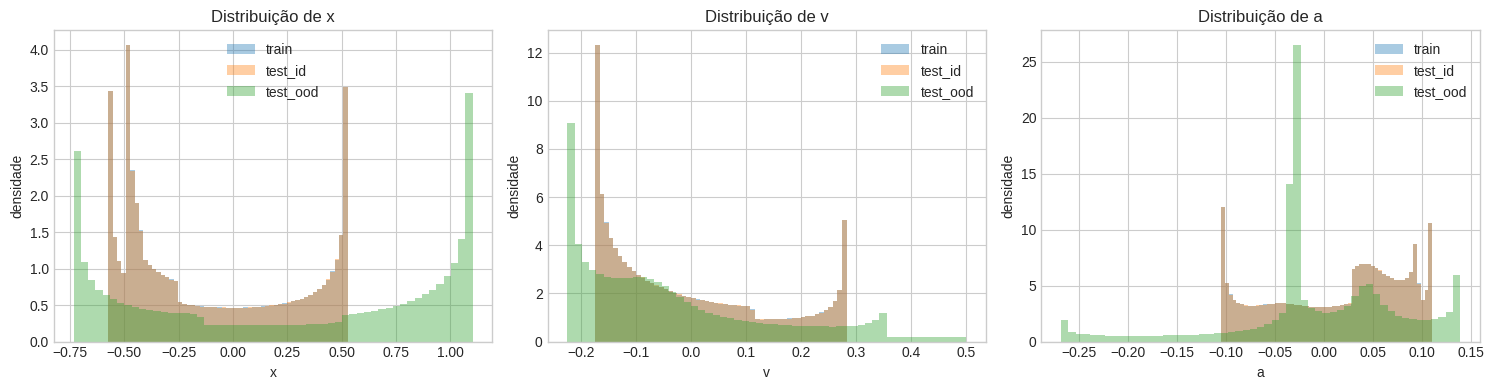

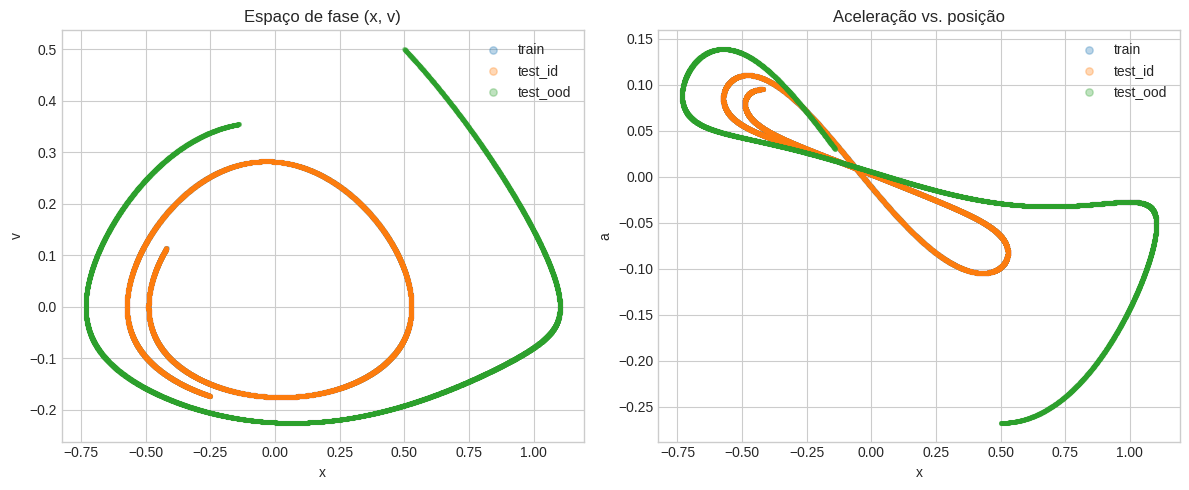

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["x", "v", "a"]):
    for name, df in sets.items():
        ax.hist(df[col], bins=55, density=True, alpha=0.38, label=name)
    ax.set(title=f"Distribuição de {col}", xlabel=col, ylabel="densidade")
    ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, df in sets.items():
    axes[0].scatter(df.x, df.v, s=7, alpha=0.3, label=name)
    axes[1].scatter(df.x, df.a, s=7, alpha=0.3, label=name)
axes[0].set(xlabel="x", ylabel="v", title="Espaço de fase (x, v)")
axes[1].set(xlabel="x", ylabel="a", title="Aceleração vs. posição")
for ax in axes: ax.legend(markerscale=2)
plt.tight_layout()
plt.show()


## 3. Estrutura dinâmica e correlações

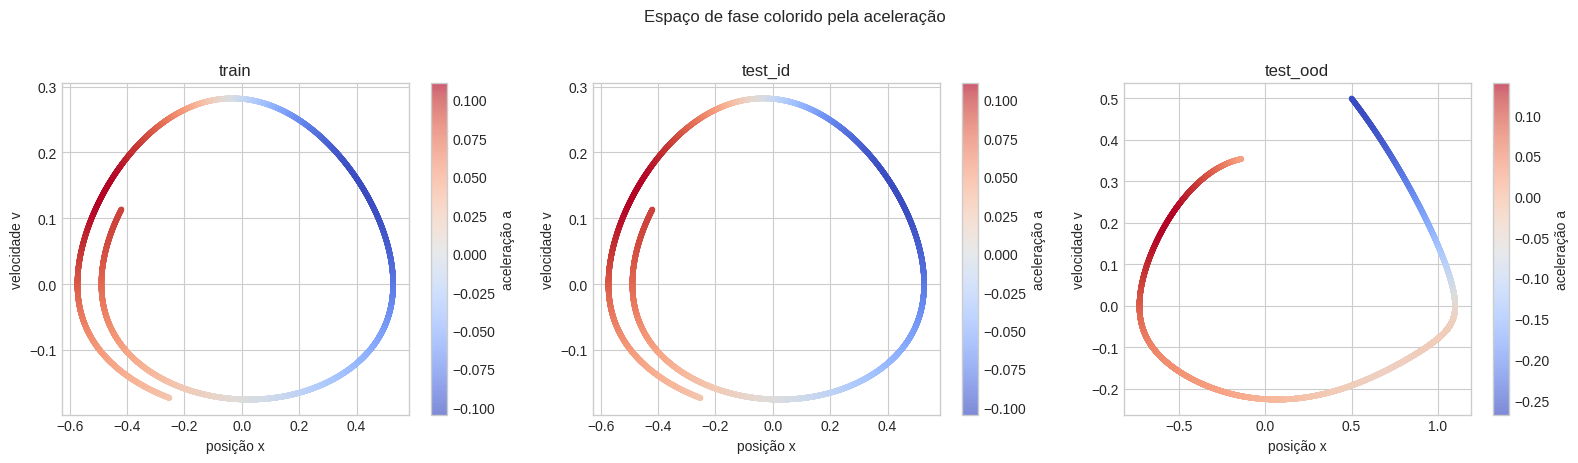

Matriz de correlação — train


,x,v,a
x,1.000,0.035,-0.951
v,0.035,1.000,-0.032
a,-0.951,-0.032,1.000


Matriz de correlação — test_id


,x,v,a
x,1.000,0.035,-0.951
v,0.035,1.000,-0.032
a,-0.951,-0.032,1.000


Matriz de correlação — test_ood


,x,v,a
x,1.000,0.018,-0.759
v,0.018,1.000,-0.219
a,-0.759,-0.219,1.000


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, ["train", "test_id", "test_ood"]):
    df = sets[name]
    points = ax.scatter(df.x, df.v, c=df.a, s=9, alpha=0.65, cmap="coolwarm")
    ax.set(title=name, xlabel="posição x", ylabel="velocidade v")
    fig.colorbar(points, ax=ax, label="aceleração a")
plt.suptitle("Espaço de fase colorido pela aceleração", y=1.02)
plt.tight_layout()
plt.show()

for name, df in sets.items():
    print(f"Matriz de correlação — {name}")
    display(df[["x", "v", "a"]].corr().round(3))


## 4. Modelos de referência para prever aceleração

Os modelos abaixo são referências empíricas, não substituem a descoberta simbólica: regressão linear em `(x, v)` e regressão polinomial de grau 2. O conjunto de treino ajusta os modelos; `test_id` e `test_ood` servem para comparar generalização. O grau 2 é apenas uma referência simples e pode não representar a física completa.

In [14]:
X_train = sets["train"][["x", "v"]].to_numpy()
y_train = sets["train"]["a"].to_numpy()
models = {
    "linear (x, v)": LinearRegression(),
    "polinômio grau 2": make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
}
rows = []
for model_name, model in models.items():
    model.fit(X_train, y_train)
    for split, df in sets.items():
        X, y = df[["x", "v"]].to_numpy(), df["a"].to_numpy()
        pred = model.predict(X)
        rows.append({"modelo": model_name, "conjunto": split,
                     "MSE": mean_squared_error(y, pred),
                     "RMSE": mean_squared_error(y, pred) ** 0.5,
                     "MAE": mean_absolute_error(y, pred),
                     "R²": r2_score(y, pred)})
metrics = pd.DataFrame(rows)
display(metrics.round(7))


,modelo,conjunto,MSE,RMSE,MAE,R²
0,"linear (x, v)",train,0.000418,0.020457,0.017309,0.904083
1,"linear (x, v)",test_id,0.000418,0.020457,0.017308,0.904084
2,"linear (x, v)",test_ood,0.006554,0.080957,0.065611,0.137415
3,polinômio grau 2,train,0.000018,0.004193,0.003646,0.995971
4,polinômio grau 2,test_id,0.000018,0.004193,0.003647,0.995970
5,polinômio grau 2,test_ood,0.006852,0.082774,0.055731,0.098259


/home/ymws/miniconda3/envs/sr-llm-integration/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but PolynomialFeatures was fitted without feature names
  warnings.warn(
/home/ymws/miniconda3/envs/sr-llm-integration/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but PolynomialFeatures was fitted without feature names
  warnings.warn(
/home/ymws/miniconda3/envs/sr-llm-integration/lib/python3.11/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but PolynomialFeatures was fitted without feature names
  warnings.warn(


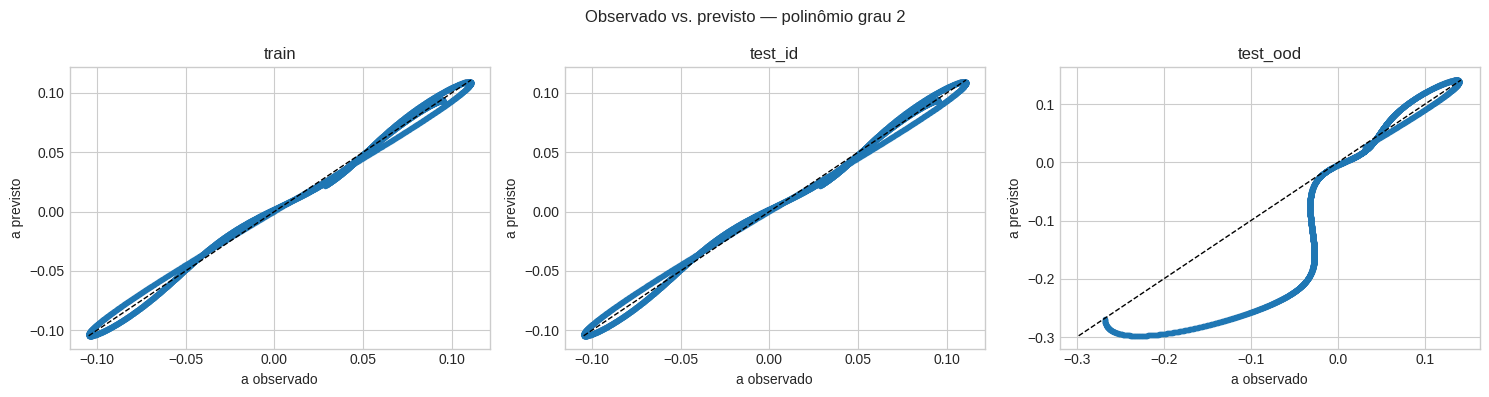

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, split in zip(axes, ["train", "test_id", "test_ood"]):
    df = sets[split]
    pred = models["polinômio grau 2"].predict(df[["x", "v"]])
    ax.scatter(df.a, pred, s=8, alpha=0.35)
    lo = min(df.a.min(), pred.min()); hi = max(df.a.max(), pred.max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set(title=split, xlabel="a observado", ylabel="a previsto")
plt.suptitle("Observado vs. previsto — polinômio grau 2")
plt.tight_layout()
plt.show()


## 5. Diagnóstico de mudança de distribuição

In [16]:
ranges = pd.DataFrame({
    name: {metric: value for col in ["x", "v", "a"] for metric, value in [(f"{col} min", df[col].min()), (f"{col} max", df[col].max())]}
    for name, df in sets.items()
}).T
display(ranges.round(5))

# Médias e desvios padrão ajudam a evidenciar mudanças entre test_id e test_ood.
shift = pd.DataFrame(index=["x", "v", "a"])
for name in ["train", "test_id", "test_ood"]:
    shift[f"{name}: média"] = sets[name][["x", "v", "a"]].mean()
    shift[f"{name}: desvio"] = sets[name][["x", "v", "a"]].std()
display(shift.round(5))


,x min,x max,v min,v max,a min,a max
train,-0.57282,0.52751,-0.17543,0.28214,-0.10468,0.11065
test_id,-0.57282,0.52751,-0.17543,0.28214,-0.10468,0.11065
test_ood,-0.73231,1.10205,-0.22538,0.50000,-0.26775,0.13904


,train: média,train: desvio,test_id: média,test_id: desvio,test_ood: média,test_ood: desvio
x,-0.10127,0.38492,-0.10126,0.38491,0.24911,0.68331
v,-0.00838,0.14490,-0.00839,0.14491,-0.03196,0.17611
a,0.01433,0.06606,0.01433,0.06606,-0.00731,0.08717


## 6. Resultados das expressões nos logs

Cada JSON em `logs/oscillator1/samples` representa uma tentativa. A célula resume a cobertura, valores de score e as melhores expressões disponíveis. Scores nulos e expressões repetidas são contabilizados; não se assume que todas as tentativas sejam comparáveis entre execuções.

Arquivos lidos: 10,001 | scores válidos: 2,434 | sem score: 7,567


,count,mean,std,min,25%,50%,75%,90%,99%,max
score,2434.0,-8.914468e+06,4.379068e+08,-2.160422e+10,-0.00427,-0.000423,-0.000419,-0.000413,-0.00002,-0.000003


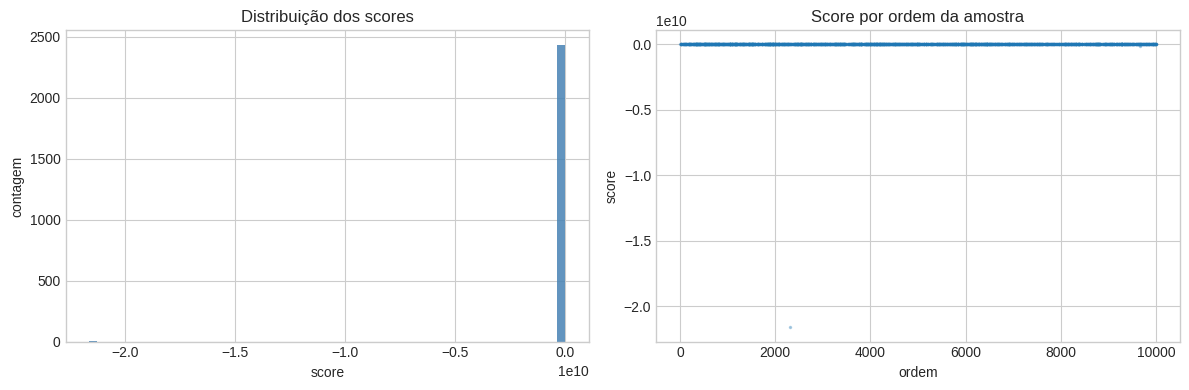

,ordem,score,arquivo
0,9352,-0.000003,samples_9352.json
1,9544,-0.000008,samples_9544.json
2,7975,-0.000011,samples_7975.json
3,6950,-0.000011,samples_6950.json
4,6149,-0.000020,samples_6149.json
5,8049,-0.000020,samples_8049.json
6,8305,-0.000020,samples_8305.json
7,8304,-0.000020,samples_8304.json
8,8755,-0.000020,samples_8755.json
9,6610,-0.000020,samples_6610.json



Amostra 9352 | score=-3.1045262e-06 | samples_9352.json
def equation(x: np.ndarray, v: np.ndarray, params: np.ndarray) -> np.ndarray:
    """ Mathematical function for acceleration in a damped nonlinear oscillator

    Args:
        x: A numpy array representing observations of current position.
        v: A numpy array representing observations of velocity.
        params: Array of numeric constants or parameters to be optimized

    Return:
        A numpy array representing acceleration as the result of applying the mathematical function to the inputs.
    """
    
    Fx = x # Position squared is here used to include jerk-like effects.
    vx = x * v # Position-multiplied-by-velocity gives x power two multiplication effect for jerk term inclusion.
    
    a = - params[1] * v + params[2] * vx + params[3] * np.sin(params[7] * Fx) + params[4] * vx
    return a



Amostra 9544 | score=-8.1432778e-06 | samples_9544.json
def equation(x: np.ndarray, v: np.ndarray, params: np.ndarray) ->

In [17]:
if SAMPLES_DIR.exists():
    records = []
    for path in sorted(SAMPLES_DIR.glob("samples_*.json")):
        try:
            obj = json.loads(path.read_text())
            records.append({"arquivo": path.name, "ordem": obj.get("sample_order"),
                            "score": obj.get("score"), "function": obj.get("function", "")})
        except (json.JSONDecodeError, OSError) as exc:
            print(f"Ignorado {path.name}: {exc}")
    log_df = pd.DataFrame(records)
    log_df["score"] = pd.to_numeric(log_df["score"], errors="coerce")
    valid = log_df.dropna(subset=["score"]).copy()
    print(f"Arquivos lidos: {len(log_df):,} | scores válidos: {len(valid):,} | sem score: {log_df.score.isna().sum():,}")
    if len(valid):
        display(valid.score.describe(percentiles=[.25, .5, .75, .9, .99]).to_frame().T.round(8))
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].hist(valid.score, bins=60, color="steelblue", alpha=.85)
        axes[0].set(title="Distribuição dos scores", xlabel="score", ylabel="contagem")
        axes[1].plot(valid.ordem, valid.score, ".", alpha=.3, ms=3)
        axes[1].set(title="Score por ordem da amostra", xlabel="ordem", ylabel="score")
        plt.tight_layout(); plt.show()
        best = valid.sort_values("score", ascending=False).head(10)
        display(best[["ordem", "score", "arquivo"]].reset_index(drop=True))
        for _, row in best.head(3).iterrows():
            print(f"\nAmostra {row['ordem']} | score={row['score']:.8g} | {row['arquivo']}\n{row['function']}")
        valid["function_normalizada"] = valid["function"].str.strip()
        print("Expressões únicas entre scores válidos:", valid.function_normalizada.nunique())
else:
    print(f"Diretório de amostras não encontrado: {SAMPLES_DIR}")


## 7. Síntese para discussão

Use as tabelas e gráficos acima para registrar as conclusões da execução: (1) como `test_ood` difere de `train`/`test_id`; (2) qual baseline generaliza melhor; (3) como os scores das expressões variam e qual a melhor expressão; e (4) se essa expressão também produz erro baixo ao ser reavaliada nos CSVs. O score do log deve ser tratado com cuidado: a especificação define score como `-loss`, mas os JSONs são resultados históricos e podem vir de configurações ou execuções diferentes.

## 8. Melhor expressão registrada vs. equação física verdadeira

A expressão verdadeira do Oscillator 1 é

$$a=F\sin(\omega x)-\alpha v^3-\beta x^3-\gamma xv-x\cos(x),$$

com os parâmetros do benchmark `F=0.8`, `ω=1.0`, `α=0.5`, `β=0.2` e `γ=0.5`. A célula mostra a melhor candidata por score, compara sua estrutura com os cinco termos verdadeiros e mede o erro da equação física nos CSVs. O score da candidata corresponde ao erro de treino, mas seus parâmetros otimizados não são salvos nos JSONs. Assim, a comparação da candidata com a equação verdadeira é estrutural; a comparação numérica nos conjuntos de teste exigiria reavaliar a candidata com seus parâmetros, que não estão registrados.


In [18]:
# Ground truth documentada para o benchmark Oscillator 1 (paper, Appendix D.1).
TRUE_PARAMS = {"F": 0.8, "omega": 1.0, "alpha": 0.5, "beta": 0.2, "gamma": 0.5}

def oscillator1_ground_truth(x, v):
    p = TRUE_PARAMS
    return (p["F"] * np.sin(p["omega"] * x)
            - p["alpha"] * v**3
            - p["beta"] * x**3
            - p["gamma"] * x * v
            - x * np.cos(x))

print("Equação física verdadeira:")
print("a = 0.8·sin(1.0·x) - 0.5·v³ - 0.2·x³ - 0.5·x·v - x·cos(x)")

# Erro da referência física frente aos dados em cada split.
truth_rows = []
for split, df in sets.items():
    y_true = df["a"].to_numpy()
    y_physics = oscillator1_ground_truth(df["x"].to_numpy(), df["v"].to_numpy())
    truth_rows.append({"conjunto": split,
                       "MSE equação física": mean_squared_error(y_true, y_physics),
                       "RMSE equação física": mean_squared_error(y_true, y_physics) ** 0.5,
                       "MAE equação física": mean_absolute_error(y_true, y_physics),
                       "R² equação física": r2_score(y_true, y_physics)})
print("\nAjuste da equação física aos valores dos CSVs:")
display(pd.DataFrame(truth_rows).set_index("conjunto").round(10))

# Melhor amostra válida de todos os logs que o notebook carregou.
if "log_df" not in globals() or log_df.empty:
    print("\nNão há arquivos de amostras para selecionar a melhor expressão.")
else:
    valid_best = log_df.dropna(subset=["score"]).copy()
    if valid_best.empty:
        print("\nOs logs existem, mas nenhum contém score numérico válido.")
    else:
        best = valid_best.sort_values("score", ascending=False).iloc[0]
        candidate = str(best["function"])
        print(f"\nMelhor candidata: amostra {int(best['ordem'])} ({best['arquivo']})")
        print(f"Score registrado: {best['score']:.10g} (score = -MSE no treino)")
        print("\nCódigo da candidata:")
        print(candidate.strip() or "(corpo da função vazio)")

        # A comparação é estrutural, usando ocorrências de operadores/variáveis
        # no código registrado. Isto não substitui equivalência algébrica.
        candidate_lower = candidate.lower().replace(" ", "")
        structure_checks = [
            ("força senoidal em x: sin(ωx)", "sin" in candidate_lower and "x" in candidate_lower),
            ("amortecimento cúbico: v³", "v**3" in candidate_lower or "v^3" in candidate_lower or "v*v*v" in candidate_lower),
            ("termo cúbico de posição: x³", "x**3" in candidate_lower or "x^3" in candidate_lower or "x*x*x" in candidate_lower),
            ("termo acoplado: x·v", ("x*v" in candidate_lower or "v*x" in candidate_lower)),
            ("termo x·cos(x)", "cos" in candidate_lower and "x" in candidate_lower),
        ]
        print("\nComparação estrutural (indícios textuais, não prova algébrica):")
        for term, found in structure_checks:
            print(f"{'Possível presença' if found else 'Não identificado'} — {term}")

        candidate_train_mse = -float(best["score"])
        truth_train_mse = truth_rows[0]["MSE equação física"]
        print(f"\nMSE da candidata no treino (inferido do score): {candidate_train_mse:.10g}")
        print(f"MSE da equação verdadeira no treino: {truth_train_mse:.10g}")
        print("A comparação numérica OOD da candidata não é calculada: os JSONs guardam o código e o score, "
              "mas não os parâmetros otimizados necessários para reproduzir suas previsões em test_id/test_ood.")


Equação física verdadeira:
a = 0.8·sin(1.0·x) - 0.5·v³ - 0.2·x³ - 0.5·x·v - x·cos(x)

Ajuste da equação física aos valores dos CSVs:


,MSE equação física,RMSE equação física,MAE equação física,R² equação física
conjunto,,,,
train,0.0,0.0,0.0,1.0
test_id,0.0,0.0,0.0,1.0
test_ood,0.0,0.0,0.0,1.0



Melhor candidata: amostra 9352 (samples_9352.json)
Score registrado: -3.104526236e-06 (score = -MSE no treino)

Código da candidata:
def equation(x: np.ndarray, v: np.ndarray, params: np.ndarray) -> np.ndarray:
    """ Mathematical function for acceleration in a damped nonlinear oscillator

    Args:
        x: A numpy array representing observations of current position.
        v: A numpy array representing observations of velocity.
        params: Array of numeric constants or parameters to be optimized

    Return:
        A numpy array representing acceleration as the result of applying the mathematical function to the inputs.
    """
    
    Fx = x # Position squared is here used to include jerk-like effects.
    vx = x * v # Position-multiplied-by-velocity gives x power two multiplication effect for jerk term inclusion.
    
    a = - params[1] * v + params[2] * vx + params[3] * np.sin(params[7] * Fx) + params[4] * vx
    return a

Comparação estrutural (indícios textuais, não 

## 9. Diferença entre a física e a candidata; comparação com PySR e gplearn

Os parâmetros numéricos otimizados das candidatas não estão nos JSONs. Quando a melhor hipótese tiver o formato `c_v*v + c_xv*x*v + c_sin*sin(omega*x)`, a célula reajusta esse esqueleto no treino e compara sua previsão com a física e com PySR/gplearn. Esse reajuste é uma nova estimativa, não os parâmetros originais do log. Se a melhor hipótese tiver outra estrutura, a célula informa a incompatibilidade e segue com a comparação da física e dos baselines, sem fingir que o modelo numérico representa a candidata. O código da hipótese e sua comparação estrutural continuam na seção anterior.

O gráfico mostra as superfícies e a diferença candidata − física na região OOD somente para o esqueleto compatível. PySR e gplearn são ajustados ao mesmo `train.csv` se as bibliotecas estiverem disponíveis.


In [ ]:
from scipy.optimize import least_squares

# Este modelo numérico representa somente o esqueleto antigo:
# c_v*v + c_xv*x*v + c_sin*sin(omega*x).
# Os parâmetros otimizados dos logs não são preservados, então o ajuste abaixo
# é uma nova estimativa feita exclusivamente no conjunto train.
candidate_text = str(candidate) if "candidate" in globals() else ""
candidate_lower = candidate_text.lower().replace(" ", "")
candidate_compatible = (
    bool(candidate_text)
    and "sin" in candidate_lower
    and "vx" in candidate_lower
    and "params[7]" in candidate_lower
)

Xtr = sets["train"][["x", "v"]].to_numpy()
ytr = sets["train"]["a"].to_numpy()

def candidate_model(X, coef):
    x, v = X[:, 0], X[:, 1]
    c_v, c_xv, c_sin, omega = coef
    return c_v * v + c_xv * x * v + c_sin * np.sin(omega * x)

model_predictions = {
    "equação física": lambda X: oscillator1_ground_truth(X[:, 0], X[:, 1]),
}
model_equations = {
    "equação física": "0.8 sin(x) - 0.5 v³ - 0.2 x³ - 0.5 x v - x cos(x)",
}

if candidate_compatible:
    starts = []
    for omega0 in [0.5, 1.0, 1.5, 2.0]:
        starts.append(least_squares(
            lambda q: candidate_model(Xtr, q) - ytr,
            x0=[-0.5, 0.0, 0.8, omega0],
            bounds=([-np.inf, -np.inf, -np.inf, 0.0], [np.inf, np.inf, np.inf, 5.0]),
            max_nfev=5000,
        ))
    candidate_fit = min(starts, key=lambda result: np.mean(result.fun ** 2))
    candidate_coef = candidate_fit.x
    print("Candidata reajustada no treino: a = c_v*v + c_xv*x*v + c_sin*sin(omega*x)")
    print(dict(zip(["c_v", "c_xv", "c_sin", "omega"], candidate_coef.round(8))))
    model_predictions["candidata (reajustada)"] = lambda X: candidate_model(X, candidate_coef)
    model_equations["candidata (reajustada)"] = (
        f"({candidate_coef[0]:.6g}) v + ({candidate_coef[1]:.6g}) x v "
        f"+ ({candidate_coef[2]:.6g}) sin(({candidate_coef[3]:.6g}) x)"
    )
else:
    print("Candidata LLM-SR não reajustada nesta seção: o código da melhor hipótese "
          "não corresponde ao esqueleto c_v*v + c_xv*x*v + c_sin*sin(omega*x).")
    print("A comparação numérica continua com a física, PySR e gplearn. "
          "A hipótese LLM-SR continua disponível estruturalmente na seção anterior.")

# Visualização das superfícies no domínio OOD. A superfície da candidata é
# incluída somente quando o formato da hipótese realmente corresponde ao modelo.
xlo, xhi = sets["test_ood"].x.min(), sets["test_ood"].x.max()
vlo, vhi = sets["test_ood"].v.min(), sets["test_ood"].v.max()
xx, vv = np.meshgrid(np.linspace(xlo, xhi, 160), np.linspace(vlo, vhi, 140))
Xgrid = np.column_stack([xx.ravel(), vv.ravel()])
a_physics_grid = oscillator1_ground_truth(Xgrid[:, 0], Xgrid[:, 1]).reshape(xx.shape)
if candidate_compatible:
    a_candidate_grid = candidate_model(Xgrid, candidate_coef).reshape(xx.shape)
    delta_grid = a_candidate_grid - a_physics_grid
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
    panels = [
        (axes[0], a_physics_grid, "Equação física verdadeira: a(x, v)", "viridis"),
        (axes[1], a_candidate_grid, "Candidata reajustada: a(x, v)", "viridis"),
        (axes[2], delta_grid, "Diferença: candidata − física", "coolwarm"),
    ]
    for ax, values, title, cmap in panels:
        im = ax.pcolormesh(xx, vv, values, shading="auto", cmap=cmap)
        fig.colorbar(im, ax=ax, label="Δa" if ax is axes[2] else "aceleração")
        ax.set(xlabel="posição x", ylabel="velocidade v", title=title)
    axes[2].contour(xx, vv, delta_grid, levels=[0], colors="black", linewidths=1)
    fig.suptitle("Comparação das acelerações na faixa OOD; Δa > 0 significa candidata acima da física")
else:
    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.pcolormesh(xx, vv, a_physics_grid, shading="auto", cmap="viridis")
    fig.colorbar(im, ax=ax, label="aceleração")
    ax.set(xlabel="posição x", ylabel="velocidade v", title="Equação física verdadeira na faixa OOD")
plt.show()

# Baselines são ajustados nos mesmos dados de treino e avaliados sem reajuste nos testes.
try:
    from pysr import PySRRegressor
    pysr_model = PySRRegressor(
        niterations=100, populations=8, population_size=33, maxsize=20,
        binary_operators=["+", "-", "*"], unary_operators=["sin", "cos"],
        verbosity=0, random_state=0,
    )
    pysr_model.fit(Xtr, ytr, variable_names=["x", "v"])
    model_predictions["PySR"] = lambda X, m=pysr_model: np.asarray(m.predict(X)).reshape(-1)
    model_equations["PySR"] = str(pysr_model.get_best()["equation"])
except Exception as exc:
    print("PySR indisponível ou falhou ao ajustar. Instale/configure PySR e Julia para incluí-lo:", repr(exc))

try:
    from gplearn.genetic import SymbolicRegressor
    gplearn_model = SymbolicRegressor(
        population_size=500, generations=20,
        function_set=["add", "sub", "mul", "div", "sin", "cos"],
        metric="mse", parsimony_coefficient=0.001,
        random_state=0, n_jobs=-1, verbose=0,
    )
    gplearn_model.fit(Xtr, ytr)
    model_predictions["gplearn"] = lambda X, m=gplearn_model: np.asarray(m.predict(X)).reshape(-1)
    model_equations["gplearn"] = str(gplearn_model._program)
except Exception as exc:
    print("gplearn indisponível ou falhou ao ajustar. Instale gplearn para incluí-lo:", repr(exc))

print("\nEquações efetivamente comparadas:")
for name, equation in model_equations.items():
    print(f"- {name}: {equation}")

comparison_rows = []
for model_name, predict in model_predictions.items():
    for split, df in sets.items():
        X = df[["x", "v"]].to_numpy()
        y = df["a"].to_numpy()
        yhat = predict(X)
        comparison_rows.append({
            "modelo": model_name, "conjunto": split,
            "MSE": mean_squared_error(y, yhat),
            "RMSE": mean_squared_error(y, yhat) ** 0.5,
            "MAE": mean_absolute_error(y, yhat),
            "R²": r2_score(y, yhat),
        })
comparison = pd.DataFrame(comparison_rows)
display(comparison.pivot(index="modelo", columns="conjunto", values=["RMSE", "MAE", "R²"]).round(8))


# Experimento controlado: recuperação da equação em trajetórias novas

Esta etapa responde a uma pergunta mais exigente que o ajuste de uma única trajetória: **cada método recupera a estrutura física em trajetórias que não viu?** Os dados são gerados integrando a equação verdadeira com várias condições iniciais. A separação é por trajetória/condição inicial, evitando que amostras quase duplicadas vazem entre treino e teste.

O protocolo roda cinco sementes. Em cada semente, os três métodos recebem exatamente as mesmas seis trajetórias de treino. Cada método tem orçamento nominal de 2.500 candidatos/indivíduos: LLM-SR recebe 2.500 amostras, PySR usa população/iterações equivalentes e gplearn usa tamanho de população × gerações equivalente. Serão reportados NMSE, RMSE, recuperação dos cinco termos, complexidade da expressão e estabilidade entre sementes. O orçamento de busca é nominal, pois os métodos contam operações internas de maneiras diferentes.

**Pré-requisitos:** dependências do projeto, `sympy`, `pysr` com Julia funcional e `gplearn`. Para LLM-SR, inicie antes o servidor local (`bash run_server.sh`) e mude `RUN_LLM_SR` para `True`. O notebook não inicia chamadas de LLM implicitamente. As saídas locais não reproduzem exatamente as execuções do artigo; elas são uma comparação nova, controlada neste conjunto de dados sintético.


In [ ]:
# Configuração reproduzível do protocolo. Ajuste os valores somente antes de iniciar a execução.
import random, ast, json, re, time
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from pathlib import Path

SEEDS = [7, 17, 23, 42, 101]
SEARCH_BUDGET = 2500
TRAJECTORY_POINTS = 300
TRAJECTORY_DURATION = 15.0
RUN_LLM_SR = False  # True requer servidor local acessível em 127.0.0.1:5000
RESULTS_DIR = ROOT / "results" / "oscillator1_controlled"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_INITIALS = [(-0.50, -0.35), (-0.50, 0.35), (0.50, -0.35), (0.50, 0.35),
                  (-0.35, -0.50), (-0.35, 0.50), (0.35, -0.50), (0.35, 0.50)]
ID_INITIALS = [(-0.20, -0.20), (-0.20, 0.20), (0.20, -0.20), (0.20, 0.20)]
OOD_INITIALS = [(-1.00, -0.80), (-1.00, 0.80), (1.00, -0.80), (1.00, 0.80)]

def simulate_oscillator(x0, v0, trajectory_id, split):
    time_grid = np.linspace(0.0, TRAJECTORY_DURATION, TRAJECTORY_POINTS)
    def rhs(t, state):
        x, v = state
        a = float(oscillator1_ground_truth(np.array([x]), np.array([v]))[0])
        return [v, a]
    sol = solve_ivp(rhs, (0.0, TRAJECTORY_DURATION), [x0, v0], t_eval=time_grid,
                    rtol=1e-9, atol=1e-11)
    if not sol.success:
        raise RuntimeError(f"Integração falhou para {trajectory_id}: {sol.message}")
    x, v = sol.y
    return pd.DataFrame({"t": sol.t, "x": x, "v": v,
                         "a": oscillator1_ground_truth(x, v),
                         "trajectory_id": trajectory_id, "split": split})

trajectory_frames = []
for split, initials in [("train_pool", TRAIN_INITIALS), ("test_id", ID_INITIALS), ("test_ood", OOD_INITIALS)]:
    for idx, (x0, v0) in enumerate(initials):
        trajectory_frames.append(simulate_oscillator(x0, v0, f"{split}_{idx}", split))
controlled_data = pd.concat(trajectory_frames, ignore_index=True)
controlled_data.to_csv(RESULTS_DIR / "trajectories.csv", index=False)

print("Trajetórias por partição:")
display(controlled_data.groupby("split").agg(
    trajetórias=("trajectory_id", "nunique"), amostras=("a", "size"),
    x_min=("x", "min"), x_max=("x", "max"), v_min=("v", "min"), v_max=("v", "max")
).round(4))


## Métricas simbólicas e segurança da leitura dos programas

A recuperação dos termos é calculada após converter as expressões para SymPy e expandir somas/produtos. Para LLM-SR, um conversor AST restrito aceita apenas operações aritméticas e chamadas matemáticas NumPy comuns; ele não executa código gerado. Os parâmetros da candidata são então reajustados no treino e mantidos fixos ao avaliar ID/OOD. Expressões que não puderem ser interpretadas com segurança são marcadas como não avaliáveis, sem descartá-las da contagem de execuções.


In [ ]:
import sympy as sp
from sympy import sin as sy_sin, cos as sy_cos, exp as sy_exp, tanh as sy_tanh, sqrt as sy_sqrt, log as sy_log
from scipy.optimize import least_squares

SX, SV = sp.symbols("x v", real=True)
TRUE_TERM_BASIS = {
    "sin(x)": sp.sin(SX),
    "v^3": SV**3,
    "x^3": SX**3,
    "x*v": SX*SV,
    "x*cos(x)": SX*sp.cos(SX),
}

def parse_llmsr_function(source):
    """Converte subset aritmético seguro do AST Python para SymPy, sem exec()."""
    tree = ast.parse(source)
    fn = next(node for node in ast.walk(tree) if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)))
    env = {"x": SX, "v": SV}
    params = {}
    def visit(node):
        if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
            return sp.Float(node.value)
        if isinstance(node, ast.Name):
            if node.id in env: return env[node.id]
            if node.id in ("x", "v"): return {"x": SX, "v": SV}[node.id]
            raise ValueError(f"Nome não permitido/indefinido: {node.id}")
        if isinstance(node, ast.Subscript) and isinstance(node.value, ast.Name) and node.value.id == "params":
            index_node = node.slice
            if isinstance(index_node, ast.Constant) and isinstance(index_node.value, int):
                i = index_node.value
                params[i] = sp.Symbol(f"p{i}", real=True)
                return params[i]
            raise ValueError("Índice de params precisa ser inteiro literal")
        if isinstance(node, ast.BinOp):
            left, right = visit(node.left), visit(node.right)
            ops = {ast.Add: lambda a,b:a+b, ast.Sub: lambda a,b:a-b, ast.Mult: lambda a,b:a*b,
                   ast.Div: lambda a,b:a/b, ast.Pow: lambda a,b:a**b}
            if type(node.op) not in ops: raise ValueError("Operador não permitido")
            return ops[type(node.op)](left, right)
        if isinstance(node, ast.UnaryOp) and isinstance(node.op, (ast.USub, ast.UAdd)):
            val = visit(node.operand)
            return -val if isinstance(node.op, ast.USub) else val
        if isinstance(node, ast.Call):
            func_name = node.func.attr if isinstance(node.func, ast.Attribute) else getattr(node.func, "id", None)
            funcs = {"sin": sp.sin, "cos": sp.cos, "tan": sp.tan, "exp": sp.exp,
                     "sqrt": sp.sqrt, "log": sp.log, "tanh": sp.tanh, "abs": sp.Abs}
            if func_name not in funcs or node.keywords:
                raise ValueError(f"Função não permitida: {func_name}")
            return funcs[func_name](*(visit(arg) for arg in node.args))
        raise ValueError(f"Construção AST não permitida: {type(node).__name__}")
    for stmt in fn.body:
        if isinstance(stmt, ast.Expr) and isinstance(stmt.value, ast.Constant) and isinstance(stmt.value.value, str):
            continue  # docstring
        if isinstance(stmt, ast.Assign) and all(isinstance(t, ast.Name) for t in stmt.targets):
            value = visit(stmt.value)
            for target in stmt.targets: env[target.id] = value
            continue
        if isinstance(stmt, ast.Return):
            return sp.simplify(visit(stmt.value)), [params[i] for i in sorted(params)]
        raise ValueError(f"Instrução não suportada: {type(stmt).__name__}")
    raise ValueError("Função sem return")

def parse_baseline_equation(text, source):
    names = {"x": SX, "v": SV, "sin": sp.sin, "cos": sp.cos, "exp": sp.exp,
             "add": lambda a,b:a+b, "sub": lambda a,b:a-b, "mul": lambda a,b:a*b,
             "div": lambda a,b:a/b, "neg": lambda a:-a}
    if source == "gplearn":
        text = text.replace("X0", "x").replace("X1", "v")
    return sp.simplify(sp.sympify(text, locals=names))

def term_recovery(expression):
    expanded = sp.expand(expression)
    found = []
    for label, target in TRUE_TERM_BASIS.items():
        match = False
        for term in sp.Add.make_args(expanded):
            _, factor = term.as_coeff_Mul()
            if sp.simplify(factor - target) == 0:
                match = True; break
        if match: found.append(label)
    return found

def expression_complexity(expression):
    return int(sp.count_ops(expression, visual=False))

def optimize_llmsr_skeleton(source, Xfit, yfit, seed):
    expression, parameters = parse_llmsr_function(source)
    fn = sp.lambdify((SX, SV, *parameters), expression, modules="numpy")
    def predict(X, coef):
        with np.errstate(all="ignore"):
            value = fn(X[:, 0], X[:, 1], *coef)
        return np.broadcast_to(np.asarray(value, dtype=float), (len(X),))
    if not parameters:
        coef = np.array([])
        return expression, parameters, coef, lambda X: predict(X, coef)
    best = None
    rng = np.random.default_rng(seed)
    starts = [np.ones(len(parameters)), np.zeros(len(parameters))]
    starts += [rng.uniform(-1, 1, len(parameters)) for _ in range(3)]
    for start in starts:
        def residual(q):
            yhat = predict(Xfit, q)
            if not np.all(np.isfinite(yhat)): return np.full(len(yfit), 1e50)
            return yhat - yfit
        try:
            result = least_squares(residual, start, max_nfev=3000)
            loss = float(np.mean(result.fun**2))
            if np.isfinite(loss) and (best is None or loss < best[0]): best = (loss, result.x)
        except (ValueError, FloatingPointError, OverflowError):
            continue
    if best is None: raise ValueError("Não foi possível reajustar parâmetros da candidata")
    coef = best[1]
    return expression, parameters, coef, lambda X: predict(X, coef)

def eval_metrics(y, yhat):
    mse = mean_squared_error(y, yhat)
    return {"MSE": mse, "NMSE": mse / np.var(y), "RMSE": mse**0.5,
            "MAE": mean_absolute_error(y, yhat), "R2": r2_score(y, yhat)}


## Rodada dos métodos clássicos

Em cada semente, seis trajetórias do conjunto de treino são selecionadas. PySR e gplearn recebem a mesma matriz e `y`; operadores permitidos são soma, subtração, multiplicação, divisão, seno e cosseno. O limite nominal de busca é ~2.500 programas por método/seed. O score é selecionado pelo erro de treino e avaliado sem reajuste nos conjuntos ID/OOD.


In [ ]:
classic_records = []
classic_equations = []
classic_status = {"PySR": "não executado", "gplearn": "não executado"}

try:
    from pysr import PySRRegressor
    HAVE_PYSR = True
except Exception as exc:
    HAVE_PYSR = False; print("PySR indisponível:", repr(exc))
try:
    from gplearn.genetic import SymbolicRegressor
    HAVE_GPLEARN = True
except Exception as exc:
    HAVE_GPLEARN = False; print("gplearn indisponível:", repr(exc))

train_pool = controlled_data[controlled_data.split == "train_pool"]
id_test = controlled_data[controlled_data.split == "test_id"]
ood_test = controlled_data[controlled_data.split == "test_ood"]
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    trajectory_ids = np.array(sorted(train_pool.trajectory_id.unique()))
    selected_ids = rng.choice(trajectory_ids, size=6, replace=False)
    train_df = train_pool[train_pool.trajectory_id.isin(selected_ids)]
    X_train = train_df[["x", "v"]].to_numpy(); y_train = train_df["a"].to_numpy()
    test_sets = {"train": train_df, "test_id": id_test, "test_ood": ood_test}

    if HAVE_PYSR:
        try:
            model = PySRRegressor(
                niterations=10, populations=5, population_size=50, maxsize=20,
                binary_operators=["+", "-", "*", "/"],
                unary_operators=["sin", "cos"], verbosity=0, random_state=seed,
            )
            started = time.time(); model.fit(X_train, y_train, variable_names=["x", "v"]); elapsed=time.time()-started
            best_row = model.get_best(); equation = str(best_row["equation"])
            expr = parse_baseline_equation(equation, "pysr")
            predict = lambda X, fitted=model: np.asarray(fitted.predict(X)).reshape(-1)
            complexity = int(best_row.get("complexity", expression_complexity(expr)))
            terms = term_recovery(expr)
            classic_status["PySR"] = "executado"
            for split, df in test_sets.items():
                X=df[["x","v"]].to_numpy(); y=df.a.to_numpy()
                classic_records.append({"method":"PySR","seed":seed,"split":split,**eval_metrics(y,predict(X)),"complexity":complexity,"terms":";".join(terms),"elapsed_sec":elapsed})
            classic_equations.append({"method":"PySR","seed":seed,"equation":equation,"terms":";".join(terms),"complexity":complexity})
        except Exception as exc:
            print(f"PySR falhou na seed {seed}:", repr(exc))

    if HAVE_GPLEARN:
        try:
            model = SymbolicRegressor(
                population_size=100, generations=25, stopping_criteria=0.0,
                function_set=["add","sub","mul","div","sin","cos"],
                metric="mse", parsimony_coefficient=0.001,
                feature_names=["x","v"], random_state=seed, n_jobs=-1, verbose=0,
            )
            started=time.time(); model.fit(X_train,y_train); elapsed=time.time()-started
            equation=str(model._program); expr=parse_baseline_equation(equation,"gplearn")
            predict=lambda X,fitted=model: np.asarray(fitted.predict(X)).reshape(-1)
            complexity=int(model._program.length_); terms=term_recovery(expr)
            classic_status["gplearn"]="executado"
            for split,df in test_sets.items():
                X=df[["x","v"]].to_numpy(); y=df.a.to_numpy()
                classic_records.append({"method":"gplearn","seed":seed,"split":split,**eval_metrics(y,predict(X)),"complexity":complexity,"terms":";".join(terms),"elapsed_sec":elapsed})
            classic_equations.append({"method":"gplearn","seed":seed,"equation":equation,"terms":";".join(terms),"complexity":complexity})
        except Exception as exc:
            print(f"gplearn falhou na seed {seed}:", repr(exc))

print("Status das bibliotecas:", classic_status)


## Rodadas pareadas de LLM-SR com RAG desligado e ligado

LLM-SR usa o mesmo pool de treino selecionado em cada semente e o mesmo orçamento de amostras nas duas condições. Para cada seed, o código executa primeiro o prompt original e depois o prompt aumentado por RAG; ambos usam o mesmo modelo local. O sampler local consulta `http://127.0.0.1:5000/completions`, então a execução fica desligada até você ativar `RUN_LLM_SR=True`. A condição RAG registra fontes em cada diretório de execução. As melhores candidatas são convertidas por uma gramática AST restrita, seus parâmetros são reajustados no treino e então avaliados sem novo ajuste em ID/OOD.


In [ ]:
llmsr_records = []
llmsr_equations = []
if RUN_LLM_SR:
    import torch
    from llmsr import pipeline as llmsr_pipeline, config as llmsr_config, sampler as llmsr_sampler, evaluator as llmsr_evaluator
    specification = (ROOT / "specs" / "specification_oscillator1_numpy.txt").read_text(encoding="utf-8")
    class_config = llmsr_config.ClassConfig(llm_class=llmsr_sampler.LocalLLM, sandbox_class=llmsr_evaluator.LocalSandbox)
    for seed in SEEDS:
        rng=np.random.default_rng(seed)
        selected_ids=rng.choice(np.array(sorted(train_pool.trajectory_id.unique())),size=6,replace=False)
        train_df=train_pool[train_pool.trajectory_id.isin(selected_ids)]
        X_train=train_df[["x","v"]].to_numpy(); y_train=train_df.a.to_numpy()
        test_sets={"train":train_df,"test_id":id_test,"test_ood":ood_test}
        for use_rag in [False, True]:
            random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
            llmsr_sampler.Sampler._global_samples_nums=1
            condition="rag" if use_rag else "baseline"
            run_dir=RESULTS_DIR / f"llmsr_seed_{seed}_{condition}"
            cfg=llmsr_config.Config(samples_per_prompt=4, use_api=False, use_rag=use_rag,
                                    problem_name="oscillator1", rag_log_dir=str(run_dir),
                                    evaluate_timeout_seconds=30)
            started=time.time()
            llmsr_pipeline.main(
                specification=specification,
                inputs=[{"data":{"inputs":X_train,"outputs":y_train}}],
                config=cfg, max_sample_nums=SEARCH_BUDGET+1, class_config=class_config, log_dir=str(run_dir),
            )
            elapsed=time.time()-started
            log_files=list((run_dir/"samples").glob("samples_*.json"))
            usable=[]
            for path in log_files:
                try:
                    record=json.loads(path.read_text())
                    if record.get("score") is not None and record.get("function"):
                        usable.append(record)
                except Exception:
                    continue
            method_name="LLM-SR + RAG" if use_rag else "LLM-SR"
            if not usable:
                print(f"Seed {seed} ({condition}): nenhum candidato válido foi gravado."); continue
            best=max(usable,key=lambda row:float(row["score"]))
            source=best["function"]
            try:
                expression, params, coef, predict=optimize_llmsr_skeleton(source,X_train,y_train,seed)
                terms=term_recovery(expression); complexity=expression_complexity(expression)
                for split,df in test_sets.items():
                    X=df[["x","v"]].to_numpy(); y=df.a.to_numpy()
                    llmsr_records.append({"method":method_name,"seed":seed,"split":split,**eval_metrics(y,predict(X)),"complexity":complexity,"terms":";".join(terms),"elapsed_sec":elapsed})
                llmsr_equations.append({"method":method_name,"seed":seed,"sample_order":best.get("sample_order"),"score":best["score"],"equation":str(expression),"python_source":source,"terms":";".join(terms),"complexity":complexity,"optimized_params":json.dumps({str(param):float(value) for param,value in zip(params,coef)})})
            except Exception as exc:
                llmsr_equations.append({"method":method_name,"seed":seed,"sample_order":best.get("sample_order"),"score":best["score"],"python_source":source,"parse_error":repr(exc)})
                print(f"Seed {seed} ({condition}): não foi possível avaliar simbolicamente a candidata:",repr(exc))
else:
    print("LLM-SR não executado. Inicie run_server.sh e defina RUN_LLM_SR=True para rodar cinco pares de condições (RAG desligado/ligado).")


## Resultados, recuperação simbólica e estabilidade

A tabela resumo usa a média e o desvio padrão entre sementes; cada semente é uma unidade experimental. A estabilidade estrutural é a fração das sementes em que cada termo foi recuperado. O arquivo de equações preserva as expressões e parâmetros reajustados para tornar a análise auditável.


In [ ]:
all_records = classic_records + llmsr_records
all_equations = classic_equations + llmsr_equations
metrics_runs = pd.DataFrame(all_records)
equations_runs = pd.DataFrame(all_equations)
if metrics_runs.empty:
    print("Nenhum método clássico foi executado. Instale PySR e gplearn; LLM-SR é opcional e requer o servidor local.")
else:
    summary = metrics_runs.groupby(["method","split"])[["NMSE","RMSE","MAE","R2","complexity","elapsed_sec"]].agg(["mean","std"]).round(6)
    display(summary)
    print("Equações descobertas por seed:")
    display(equations_runs[[c for c in ["method","seed","equation","terms","complexity","score","sample_order"] if c in equations_runs.columns]])

    stability_rows=[]
    for method, group in equations_runs.groupby("method"):
        analyzed=group.dropna(subset=["terms"]) if "terms" in group.columns else group.iloc[0:0]
        valid_seeds=analyzed.seed.nunique()
        for term in TRUE_TERM_BASIS:
            recovered=sum(term in str(value).split(";") for value in analyzed.get("terms",[]))
            stability_rows.append({"method":method,"termo verdadeiro":term,"sementes que recuperaram":recovered,
                                   "total de seeds com expressão analisável":valid_seeds,
                                   "frequência":recovered/valid_seeds if valid_seeds else np.nan})
    stability=pd.DataFrame(stability_rows)
    display(stability.pivot(index="termo verdadeiro",columns="method",values="frequência").round(2))

    metrics_runs.to_csv(RESULTS_DIR / "metrics_by_seed.csv",index=False)
    equations_runs.to_json(RESULTS_DIR / "equations_by_seed.json",orient="records",force_ascii=False,indent=2)
    stability.to_csv(RESULTS_DIR / "term_recovery_stability.csv",index=False)
    print("Resultados salvos em:",RESULTS_DIR)
